# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

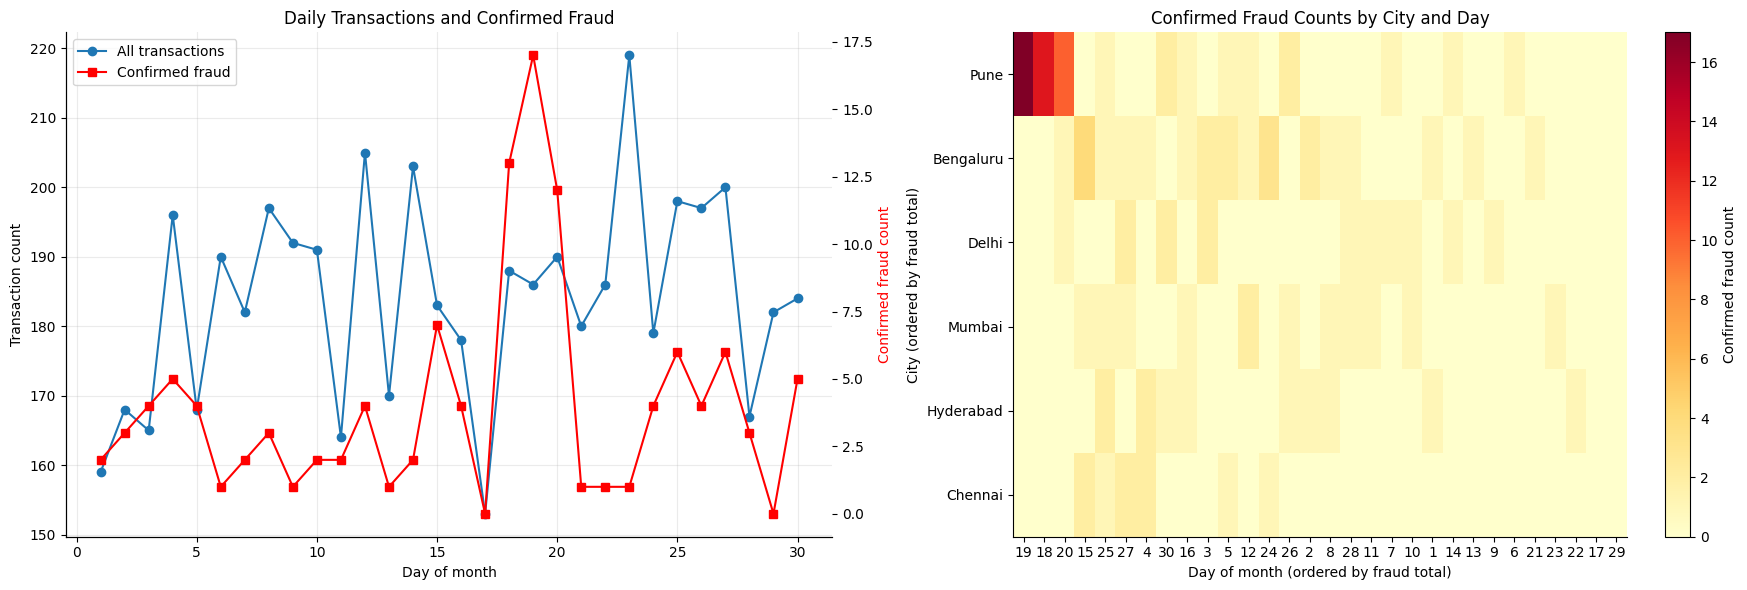

Top 10 city-day combinations by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
Chennai    4       2
Bengaluru  3       2
Hyderabad  25      2
Pune       26      2
Chennai    15      2


In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
# TODO 1: Daily transaction counts and confirmed fraud
daily_counts = tx.groupby("day").size()
daily_fraud = tx.groupby("day")["is_fraud"].sum()

axes[0].plot(
    daily_counts.index, daily_counts.values,
    marker="o", label="All transactions"
)
axes[0].set_ylabel("Transaction count")
axes[0].set_xlabel("Day of month")
axes[0].set_title("Daily Transactions and Confirmed Fraud")
axes[0].grid(True, alpha=0.25)

ax2 = axes[0].twinx()
ax2.plot(
    daily_fraud.index, daily_fraud.values,
    color="red", marker="s", label="Confirmed fraud"
)
ax2.set_ylabel("Confirmed fraud count", color="red")

lines1, labels1 = axes[0].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[0].legend(lines1 + lines2, labels1 + labels2, loc="upper left")


# TODO 2: City × day matrix of confirmed fraud counts
heat = tx.pivot_table(
    index="city",
    columns="day",
    values="is_fraud",
    aggfunc="sum",
    fill_value=0
)

# Reorder cities and days by their total confirmed fraud counts
heat = heat.loc[
    heat.sum(axis=1).sort_values(ascending=False).index,
    heat.sum(axis=0).sort_values(ascending=False).index
]

im = axes[1].imshow(
    heat.values,
    aspect="auto",
    interpolation="nearest",
    cmap="YlOrRd"
)

axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns)
axes[1].set_xlabel("Day of month (ordered by fraud total)")
axes[1].set_ylabel("City (ordered by fraud total)")
axes[1].set_title("Confirmed Fraud Counts by City and Day")
fig.colorbar(im, ax=axes[1], label="Confirmed fraud count")


plt.tight_layout()
plt.show()


# TODO 3: Print the city-day cells with the most fraud
top_cells = (
    tx.groupby(["city", "day"])["is_fraud"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("Top 10 city-day combinations by confirmed fraud:")
print(top_cells.to_string())


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_The overview revealed a concentration of confirmed fraud in Pune, particularly on days 18–20, which an alert list sorted by detector score might not make obvious. The city-by-day heatmap makes this cluster visible across the whole month instead of focusing on individual transactions. This demonstrates the concept of **overview first**, followed by zooming and filtering, as described by Shneiderman's mantra. Reordering the matrix rows and columns by their totals also makes patterns easier to identify, illustrating the lecture concept of a reordered matrix.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

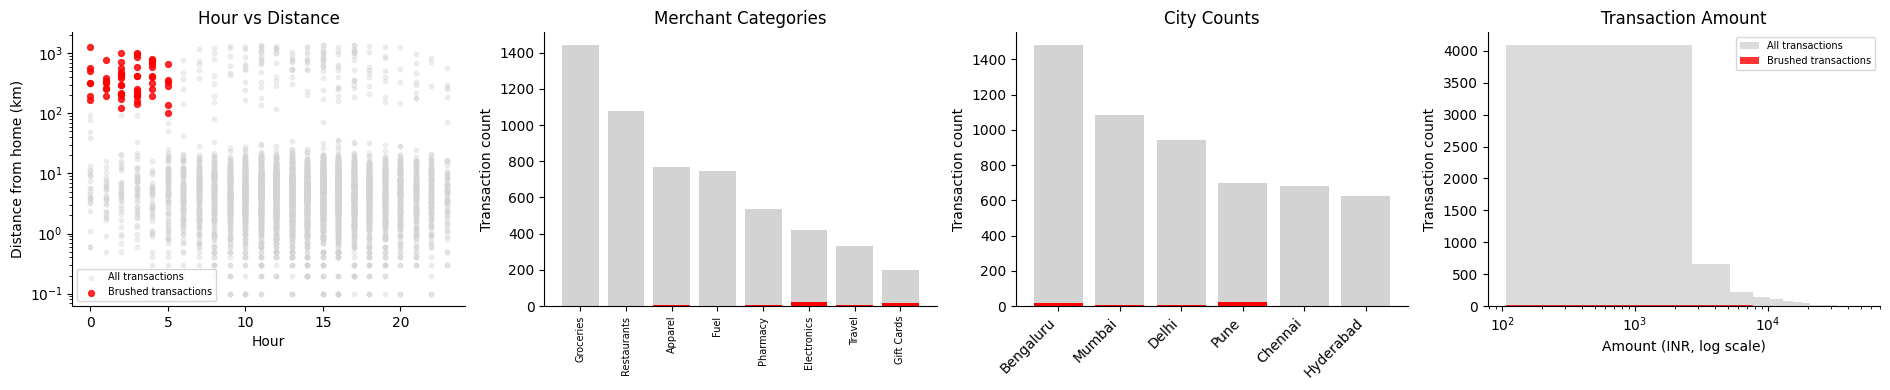

Transactions inside brush: 61
Fraud rate inside brush: 86.89%
Overall fraud rate: 2.17%
Share of all fraud captured by brush: 44.17%


In [4]:
# TODO 1: Define the brush
brush = (tx["night"] == True) & (tx["distance_from_home_km"] > 100)
brushed = tx[brush]

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2(a): Hour vs. distance scatter plot
axes[0].scatter(
    tx["hour"], tx["distance_from_home_km"],
    color="lightgrey", alpha=0.35, s=10, label="All transactions"
)
axes[0].scatter(
    brushed["hour"], brushed["distance_from_home_km"],
    color="red", alpha=0.8, s=18, label="Brushed transactions"
)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs Distance")
axes[0].legend(fontsize=7)

# TODO 2(b): Merchant category counts
all_merchant = tx["merchant_category"].value_counts()
brush_merchant = brushed["merchant_category"].value_counts()

merchant_order = all_merchant.index
axes[1].bar(
    range(len(merchant_order)),
    all_merchant.reindex(merchant_order).values,
    color="lightgrey", label="All"
)
axes[1].bar(
    range(len(merchant_order)),
    brush_merchant.reindex(merchant_order, fill_value=0).values,
    color="red", label="Brushed"
)
axes[1].set_xticks(range(len(merchant_order)))
axes[1].set_xticklabels(merchant_order, rotation=90, fontsize=7)
axes[1].set_ylabel("Transaction count")
axes[1].set_title("Merchant Categories")

# TODO 2(c): City counts
all_city = tx["city"].value_counts()
brush_city = brushed["city"].value_counts()

city_order = all_city.index
axes[2].bar(
    range(len(city_order)),
    all_city.reindex(city_order).values,
    color="lightgrey", label="All"
)
axes[2].bar(
    range(len(city_order)),
    brush_city.reindex(city_order, fill_value=0).values,
    color="red", label="Brushed"
)
axes[2].set_xticks(range(len(city_order)))
axes[2].set_xticklabels(city_order, rotation=45, ha="right")
axes[2].set_ylabel("Transaction count")
axes[2].set_title("City Counts")

# TODO 2(d): Amount histogram
bins = np.histogram_bin_edges(tx["amount_inr"], bins=20)

axes[3].hist(
    tx["amount_inr"], bins=bins,
    color="lightgrey", alpha=0.8, label="All transactions"
)
axes[3].hist(
    brushed["amount_inr"], bins=bins,
    color="red", alpha=0.8, label="Brushed transactions"
)
axes[3].set_xscale("log")
axes[3].set_xlabel("Amount (INR, log scale)")
axes[3].set_ylabel("Transaction count")
axes[3].set_title("Transaction Amount")
axes[3].legend(fontsize=7)

plt.tight_layout()
plt.show()

# TODO 3: Print brush statistics
brush_count = len(brushed)
brush_fraud_rate = brushed["is_fraud"].mean()
overall_fraud_rate = tx["is_fraud"].mean()

fraud_captured = brushed["is_fraud"].sum()
total_fraud = tx["is_fraud"].sum()
fraud_share = fraud_captured / total_fraud if total_fraud else 0

print(f"Transactions inside brush: {brush_count}")
print(f"Fraud rate inside brush: {brush_fraud_rate:.2%}")
print(f"Overall fraud rate: {overall_fraud_rate:.2%}")
print(f"Share of all fraud captured by brush: {fraud_share:.2%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_The brush identified 61 transactions, with a fraud rate of **86.89%**, compared with an overall fraud rate of **2.17%**. However, it captured only **44.17% of all confirmed fraud** (53 out of 120 cases), meaning that 56 out of 120 fraud cases fell outside this rule. Therefore, investigators should use the rule to prioritize suspicious transactions, not as their only fraud-detection strategy. The city view helps identify geographic patterns, while the overview heatmap from Task 1 revealed additional fraud concentration in Pune. This demonstrates the value of **linked highlighting**: multiple views provide context that a single rule cannot.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [5]:

# Build approximately 1 million rows
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Measure the filter time; take the best of 5 runs
filter_times = []

for _ in range(5):
    start = time.perf_counter()

    mask = (
        (big["detector_score"] >= 0.6) &
        (big["amount_inr"] > 3000)
    )
    filtered = big[mask]

    elapsed = time.perf_counter() - start
    filter_times.append(elapsed)

best_s = min(filter_times)

# TODO 2: Per-item cost and maximum rows within 0.1 seconds
per_item_us = (best_s / len(big)) * 1_000_000
max_rows = 0.1 / (best_s / len(big))

# TODO 3: Estimate performance for 50 million rows
t_50m = (best_s / len(big)) * 50_000_000
skip_pct = max(0, (1 - (0.1 / t_50m)) * 100)

print(
    f"{len(big):,} rows in {best_s*1000:.1f} ms "
    f"-> {per_item_us:.4f} us/row "
    f"-> max {max_rows:,.0f} rows in 0.1 s"
)
print(
    f"50M rows -> {t_50m:.2f} s; "
    f"must skip {skip_pct:.1f}% of rows to stay under 0.1 s"
)


1,004,640 rows in 10.6 ms -> 0.0105 us/row -> max 9,490,181 rows in 0.1 s
50M rows -> 0.53 s; must skip 81.0% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_One useful reduce technique is **pre-aggregation**, where transactions are summarized into groups before visualization. This reduces the amount of data the slider needs to process and can improve responsiveness on 50 million rows. However, the analyst loses transaction-level detail and may not be able to inspect individual suspicious transactions from the aggregated view. A practical solution is to use aggregated summaries for instant exploration and retrieve individual transactions when the analyst zooms in.


## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

Threshold evaluation:
 threshold  alerts  TP   FP  FN  precision  recall    F1
      0.05    2012 114 1898   6      0.057   0.950 0.107
      0.10    1167 111 1056   9      0.095   0.925 0.172
      0.15     786 110  676  10      0.140   0.917 0.243
      0.20     596 106  490  14      0.178   0.883 0.296
      0.25     471 105  366  15      0.223   0.875 0.355
      0.30     401 104  297  16      0.259   0.867 0.399
      0.35     355 104  251  16      0.293   0.867 0.438
      0.40     319 104  215  16      0.326   0.867 0.474
      0.45     283 104  179  16      0.367   0.867 0.516
      0.50     260 101  159  19      0.388   0.842 0.532
      0.55     235  97  138  23      0.413   0.808 0.546
      0.60     215  96  119  24      0.447   0.800 0.573
      0.65     197  94  103  26      0.477   0.783 0.593
      0.70     189  93   96  27      0.492   0.775 0.602
      0.75     170  87   83  33      0.512   0.725 0.600
      0.80     144  84   60  36      0.583   0.700 0.636
      0.8

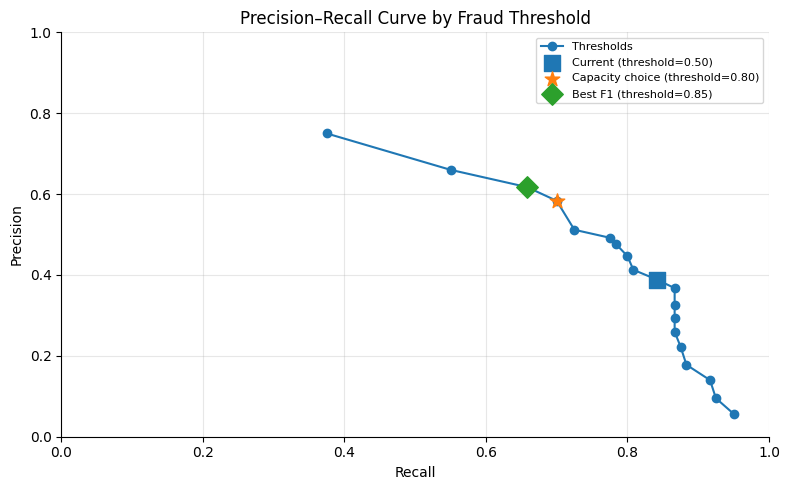

Recommendation: use threshold 0.80; it generates 144 alerts, with precision 58.3%, recall 70.0%, and F1 0.636, while staying within the 150-alert capacity.


In [6]:

rows = []

# TODO 1: Evaluate thresholds from 0.05 to 0.95
y_true = tx["is_fraud"].astype(bool)

for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2):
    y_pred = tx["detector_score"] >= threshold

    tp = int((y_pred & y_true).sum())
    fp = int((y_pred & ~y_true).sum())
    fn = int((~y_pred & y_true).sum())

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    rows.append({
        "threshold": threshold,
        "alerts": int(y_pred.sum()),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })

pr = pd.DataFrame(rows)

# TODO 2: Highest recall under the 150-alert capacity
eligible = pr[pr["alerts"] <= 150]

if eligible.empty:
    raise ValueError("No threshold meets the 150-alert capacity.")

capacity_choice = eligible.sort_values(
    ["recall", "threshold"],
    ascending=[False, True]
).iloc[0]

# Best-F1 threshold
best_f1 = pr.loc[pr["F1"].idxmax()]

print("Threshold evaluation:")
print(pr.round(3).to_string(index=False))

print("\nCapacity-constrained choice:")
print(capacity_choice.to_string())

print("\nBest-F1 choice:")
print(best_f1.to_string())

# TODO 3: Precision-recall curve with the three choices marked
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    pr["recall"], pr["precision"],
    marker="o", label="Thresholds"
)

def mark_threshold(row, label, marker):
    ax.scatter(
        row["recall"], row["precision"],
        s=120, marker=marker,
        label=f"{label} (threshold={row['threshold']:.2f})",
        zorder=3
    )

current = pr.loc[pr["threshold"] == 0.50].iloc[0]

mark_threshold(current, "Current", "s")
mark_threshold(capacity_choice, "Capacity choice", "*")
mark_threshold(best_f1, "Best F1", "D")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Curve by Fraud Threshold")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# TODO 4: Recommendation
print(
    f"Recommendation: use threshold {capacity_choice['threshold']:.2f}; "
    f"it generates {int(capacity_choice['alerts'])} alerts, "
    f"with precision {capacity_choice['precision']:.1%}, "
    f"recall {capacity_choice['recall']:.1%}, "
    f"and F1 {capacity_choice['F1']:.3f}, "
    "while staying within the 150-alert capacity."
)


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_The Head of Fraud Ops should make the final threshold decision, using the model's metrics as evidence. The capacity-constrained threshold of **0.80** produces 144 alerts, with 58.3% precision and 70% recall. The best-F1 threshold of **0.85** produces 128 alerts, with 61.7% precision and 65.8% recall. Although the best-F1 threshold has slightly better overall balance, the 0.80 threshold catches more confirmed fraud while remaining within the team's alert capacity. Visual analytics keeps a human in the loop because the final decision must balance missed fraud, false alarms, and available investigative resources rather than optimize a metric alone.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [7]:

# TODO 1: Interactive scatter plot of transactions with detector_score >= 0.3
flagged = tx[tx["detector_score"] >= 0.3].copy()

fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data={
        "txn_id": True,
        "customer_id": True,
        "city": True,
        "merchant_category": True,
        "distance_from_home_km": True,
        "detector_score": ":.3f",
        "timestamp": True,
        "amount_inr": ":.2f"
    },
    title="Flagged Transactions: Interactive Investigation"
)

fig_scatter.update_layout(
    dragmode="select",
    xaxis_title="Timestamp",
    yaxis_title="Transaction Amount (INR, log scale)"
)

fig_scatter.show()


# TODO 2: Interactive sunburst — city → merchant category
sunburst_data = (
    flagged.groupby(["city", "merchant_category"], as_index=False)
    .agg(
        transaction_count=("txn_id", "count"),
        fraud_rate=("is_fraud", "mean")
    )
)

fig_sunburst = px.sunburst(
    sunburst_data,
    path=["city", "merchant_category"],
    values="transaction_count",
    color="fraud_rate",
    color_continuous_scale="RdYlGn_r",
    range_color=(0, 1),
    hover_data={
        "transaction_count": True,
        "fraud_rate": ":.1%"
    },
    title="Flagged Transactions: City → Merchant Category"
)

fig_sunburst.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_Tooltips are useful for inspecting an individual transaction, but checking hundreds of cases one by one is slow and makes overall patterns difficult to recognize. Investigators may miss clusters by city, time, transaction amount, or merchant category. The overview heatmap from Task 1 addresses this by presenting many transactions together and highlighting concentrations of confirmed fraud. The interactive scatter plot and sunburst complement that overview by allowing investigators to zoom in and inspect details on demand.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

HYPOTHESIS TEST
---------------------------------------------
Transactions inside window: 107
Fraud rate inside window:   37.38%
Transactions outside:       5413
Fraud rate outside window:  1.48%
Chi-square statistic:       619.294
P-value:                    0.000000

COUNTER-EXAMPLE SEARCH
                   group  transactions  fraud_count fraud_rate
        Pune, days 18–20           107           40     37.38%
        Pune, other days           593           11      1.85%
Other cities, days 18–20           457            2      0.44%
Other cities, other days          4363           67      1.54%


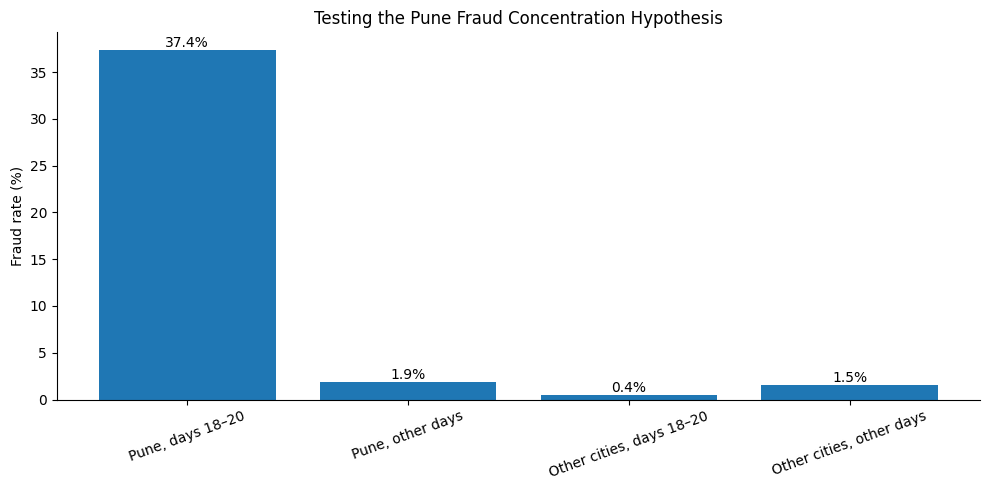


VERDICT
---------------------------------------------
The suspected window has a statistically significant higher fraud rate.
The concentration warrants further investigation, but does not prove
that a coordinated fraud ring exists.


In [8]:

from scipy.stats import chi2_contingency

# TODO 1: Hypothesis — fraud was unusually concentrated in Pune on days 18–20
in_window = (
    (tx["city"] == "Pune") &
    (tx["day"].between(18, 20))
)

# TODO 2: Compare fraud rates inside vs. outside the suspected window
inside = tx.loc[in_window, "is_fraud"]
outside = tx.loc[~in_window, "is_fraud"]

inside_rate = inside.mean()
outside_rate = outside.mean()

contingency_table = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("HYPOTHESIS TEST")
print("-" * 45)
print(f"Transactions inside window: {len(inside)}")
print(f"Fraud rate inside window:   {inside_rate:.2%}")
print(f"Transactions outside:       {len(outside)}")
print(f"Fraud rate outside window:  {outside_rate:.2%}")
print(f"Chi-square statistic:       {chi2:.3f}")
print(f"P-value:                    {p_value:.6f}")

# TODO 3: Search for counter-examples
same_city_other_days = (
    (tx["city"] == "Pune") &
    (~tx["day"].between(18, 20))
)

other_cities_same_days = (
    (tx["city"] != "Pune") &
    (tx["day"].between(18, 20))
)

rest = (
    (tx["city"] != "Pune") &
    (~tx["day"].between(18, 20))
)

groups = {
    "Pune, days 18–20": in_window,
    "Pune, other days": same_city_other_days,
    "Other cities, days 18–20": other_cities_same_days,
    "Other cities, other days": rest
}

group_stats = []
for group_name, mask in groups.items():
    subset = tx.loc[mask, "is_fraud"]
    group_stats.append({
        "group": group_name,
        "transactions": len(subset),
        "fraud_count": int(subset.sum()),
        "fraud_rate": subset.mean() if len(subset) else 0
    })

group_df = pd.DataFrame(group_stats)
print("\nCOUNTER-EXAMPLE SEARCH")
print(group_df.to_string(
    index=False,
    formatters={"fraud_rate": "{:.2%}".format}
))

# TODO 4: Visual confirmation
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    group_df["group"],
    group_df["fraud_rate"] * 100
)
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Testing the Pune Fraud Concentration Hypothesis")
ax.tick_params(axis="x", rotation=20)

for bar, rate in zip(bars, group_df["fraud_rate"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1%}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# TODO 5: Verdict — statistical association is not proof of a fraud ring
window_rate = group_df.loc[0, "fraud_rate"]
same_city_rate = group_df.loc[1, "fraud_rate"]
same_days_rate = group_df.loc[2, "fraud_rate"]

print("\nVERDICT")
print("-" * 45)

if p_value < 0.05 and inside_rate > outside_rate:
    print("The suspected window has a statistically significant higher fraud rate.")
    print("The concentration warrants further investigation, but does not prove")
    print("that a coordinated fraud ring exists.")
else:
    print("The data does not establish a statistically significant higher fraud")
    print("rate in the suspected window. The fraud-ring hypothesis is not supported")
    print("by this test alone.")

if same_city_rate >= inside_rate:
    print("Counter-example: Pune also has a high fraud rate outside days 18–20.")
    print("Consider a persistent city-level pattern as an alternative explanation.")

if same_days_rate >= inside_rate:
    print("Counter-example: other cities also have a high fraud rate on days 18–20.")
    print("Consider a broader time-related pattern as an alternative explanation.")


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_The search for fraud in Pune on days 18–20 would be weakened if the same city had similarly high fraud rates on other days, because that would suggest a persistent city-level issue rather than a specific fraud-ring event. The second counter-example is also important: if other cities experienced similarly high fraud rates on days 18–20, a broader time-related event or detector behavior could explain the spike. These checks help prevent confirmation bias. Even if the statistical test is significant, the result shows an association, not proof of a coordinated fraud ring.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_Last month, the dataset contained 5,520 transactions, including 120 confirmed fraud cases (2.17%), with a notable concentration in Pune on days 18–20. I recommend a detector threshold of **0.80**, which generates 144 alerts within the 150-alert capacity, achieving 58.3% precision and 70% recall; investigators should review alerts before taking action, keeping a human in the loop. I would build the **interactive scatter plot** first because investigators can explore transaction amounts over time, filter suspicious cases through linked brushing, and inspect individual records using details-on-demand. This combines an overview of flagged transactions with interactive exploration, reducing the effort needed to investigate cases individually. Finally, introduce a **feedback loop** in which investigators label reviewed alerts as fraud or legitimate and use those outcomes to evaluate and improve the detector's thresholds and performance for the next month.
